<a href="https://colab.research.google.com/github/jubayerkhan/Node-API/blob/main/Assignment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 3: Non-Linear Models and Validation Metrics (50 marks total)
### Due: October 30 at 11:59pm

### Name:

### In this assignment, you will need to write code that uses non-linear models to perform classification and regression tasks. You will also be asked to describe the process by which you came up with the code. More details can be found below. Please cite any websites or AI tools that you used to help you with this assignment.

## Part 1: Classification (30 marks)

### *Part 1A: Decision Function*

Building on the first part of the previous assignment, we would like to test how changing the decision boundary for a linear model impacts the results.

### Step 0: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings('ignore') #ignoring some deprication warnings

### Step 1: Data Input (1 mark)

Load data using the same method as assignment 2.

In [3]:
# TO DO: Import spam dataset from yellowbrick library
import yellowbrick.datasets as yb_dataset
X, y = yb_dataset.loaders.load_spam(data_home=None, return_dataset=False)

# TO DO: Print the size of X and y (0.5 marks)
print('X:', X.shape, type(X))
print('y:', y.shape, type(y))


X: (4600, 57) <class 'pandas.core.frame.DataFrame'>
y: (4600,) <class 'pandas.core.series.Series'>


Next, we need to split the data into training and testing sets.

In [4]:
# TO DO: Split 10% of the data for the testing set (1 mark)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

### Step 2: Data Processing
Based on assignment 2, follow the same data processing steps (if needed)

In [5]:
# TO DO: Data processing steps (if needed)
# FROM REPO: 'Linear Models/Linear Example_old2.ipynb' checks for missing values with data.info()
X.info()
y.info()

print(f'\nCount of NULL records in X\n{X.isnull().sum()}')
print(f'\nCount of NA records in X\n{X.isna().sum()}')

print(f'\nCount of NA records in y\n{y.isna().sum()}')
print(f'\nCount of NULL records in y\n{y.isnull().sum()}')
# Every column says 4600 non-null, so there is nothing to fill in for the spam data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 57 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4600 non-null   float64
 1   word_freq_address           4600 non-null   float64
 2   word_freq_all               4600 non-null   float64
 3   word_freq_3d                4600 non-null   float64
 4   word_freq_our               4600 non-null   float64
 5   word_freq_over              4600 non-null   float64
 6   word_freq_remove            4600 non-null   float64
 7   word_freq_internet          4600 non-null   float64
 8   word_freq_order             4600 non-null   float64
 9   word_freq_mail              4600 non-null   float64
 10  word_freq_receive           4600 non-null   float64
 11  word_freq_will              4600 non-null   float64
 12  word_freq_people            4600 non-null   float64
 13  word_freq_report            4600 

### Step 3: Implement Machine Learning Model (2 marks)

1. Import `LogisticRegression` from sklearn
1. Instantiate model `LogisticRegression(max_iter=2000)`
1. Split training data into training and validation sets (use 20% of the data for validation)
1. Train the machine learning model

In [6]:
# TO DO: Split training data into training and validation sets and fit model to training data (2 marks)
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=2000)
X_train_split, X_val, y_train_split, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

print(f'Training set size: {X_train_split.shape}, Validation set size: {X_val.shape}')
model.fit(X_train_split, y_train_split)

Training set size: (3312, 57), Validation set size: (828, 57)


LogisticRegression(max_iter=2000)

### Step 4-5: Validate Model and Visualize Results (4 marks)

Next, we can print the classification report and confusion matrix for this data set using the training and validation data.

In [7]:
# TO DO: Print classification report (1 mark)

from sklearn.metrics import classification_report

y_pred = model.predict(X_val)
print(classification_report(y_val, y_pred))


              precision    recall  f1-score   support

           0       0.95      0.95      0.95       494
           1       0.92      0.92      0.92       334

    accuracy                           0.94       828
   macro avg       0.93      0.93      0.93       828
weighted avg       0.94      0.94      0.94       828



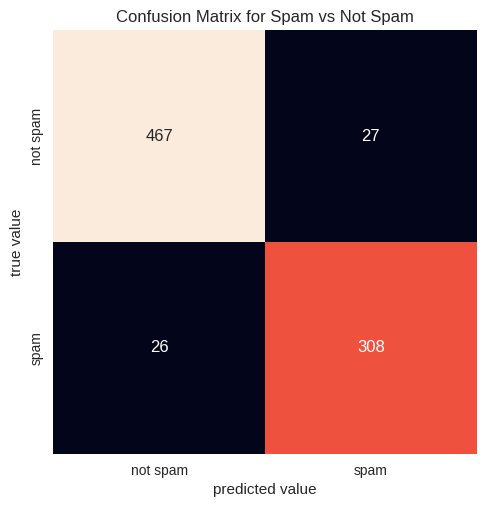

TN 467 FP 27 FN 26 TP 308


In [8]:
# TO DO: Print confusion matrix (1 mark)
from sklearn.metrics import confusion_matrix

mat = confusion_matrix(y_val, y_pred)
sns.heatmap(mat, xticklabels=['not spam', 'spam'], yticklabels=['not spam', 'spam'],
            square=True, annot=True, fmt='d', cbar=False)
plt.xlabel('predicted value')
plt.ylabel('true value')
plt.title("Confusion Matrix for Spam vs Not Spam")
plt.show()
tn, fp, fn, tp = mat.ravel()
print('TN', tn, 'FP', fp, 'FN', fn, 'TP', tp)

In this case, do we want to increase precision or recall? Based on your choice, select the appropriate direction to adjust the decision boundary. You can use either 1 or -1 as your new threshold, depending on your selected direction.

In [9]:
# TO DO: Predict values based on new decision function threshold and print classification report (1 mark)
y_pred_increase_thresh = model.decision_function(X_val) > 1
print(classification_report(y_val, y_pred_increase_thresh))

              precision    recall  f1-score   support

           0       0.88      0.97      0.93       494
           1       0.95      0.81      0.88       334

    accuracy                           0.91       828
   macro avg       0.92      0.89      0.90       828
weighted avg       0.91      0.91      0.91       828



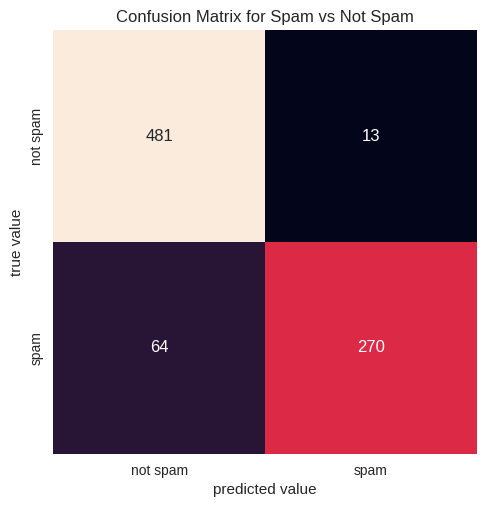

TN 481 FP 13 FN 64 TP 270


In [10]:
# TO DO: Print new confusion matrix (1 mark)
mat = confusion_matrix(y_val, y_pred_increase_thresh)
sns.heatmap(mat, xticklabels=['not spam', 'spam'], yticklabels=['not spam', 'spam'],
            square=True, annot=True, fmt='d', cbar=False)
plt.xlabel('predicted value')
plt.ylabel('true value')
plt.title("Confusion Matrix for Spam vs Not Spam")
plt.show()
tn, fp, fn, tp = mat.ravel()
print('TN', tn, 'FP', fp, 'FN', fn, 'TP', tp)

### Questions (6 marks)
1. Did you decide to move the threshold to increase recall or precision? Why?
1. How did your decision impact the number of false negatives and false positives? What is a potential unintended consequence of changing the decision boundary in this context?
1. Why did we use the validation data instead of the test data to check the new decision threshold?

**Answers:-**
1. We decided to move the threshold to increase precision because we do not want that an important email to be marked as spam.
1. The decision to move the threshold to increase precision increased the number of false negatives (26 to 64) but decreased the number of false positives (27 to 13). The unintended consequence of this is that less "not spam" emails will be identified as "spam" emails but there will be more "spam" emails that will be identified as "not spam" and pass-through.
1. We used validation data to check the new decision threshold instead of the test data because we do not want the model to learn about the patterns of the unknown data will be used to test the model causing information leakage.

### *Part 1B: Non-linear classification*

Using the spam dataset from part 1A, compare the performance of two non-linear models to the linear model used in assignment 2.

### Step 3: Implement Machine Learning Models

1. Import `LogisticRegression`, `SVC` and `RandomForestClassifier` from sklearn
2. Instantiate models as `LogisticRegression(max_iter=2000)`, `SVC()` and `RandomForestClassifier(random_state=0, max_depth=10)`
3. Implement the machine learning models

### Step 4: Validate Model

Calculate the training and validation accuracy for the three different models mentioned in Step 3. For this case, you can use `cross_validate()` with `cv=5` and `scoring='accuracy'` to get the training and validation data for each of the three models and calculate the accuracy results.

### Step 5.1: Visualize Results (4 marks)

1. Create a pandas DataFrame `results` with columns: Training accuracy and Validation accuracy
1. Add the training accuracy and validation accuracy for each model to the `results` DataFrame
1. Add the model names as the index for the DataFrame
1. Print `results`

In [11]:
# TO DO: ADD YOUR CODE HERE FOR STEPS 3-5
# HINT: USING A LOOP TO STORE THE DATA IN YOUR RESULTS DATAFRAME WILL BE MORE EFFICIENT

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate

lr = LogisticRegression(max_iter=2000)
svc = SVC()
rfc = RandomForestClassifier(random_state=0, max_depth=10)

datasets = {
    'LogisticRegression' : lr,
    'SVC' : svc,
    'RandomForestClassifier' : rfc
}

results = pd.DataFrame(columns=['Training accuracy', 'Validation accuracy'])
for model_name, model in datasets.items():
    scores = cross_validate(model, X_train, y_train, cv=5, scoring='accuracy', return_train_score=True)
    results.loc[model_name] = [scores['train_score'].mean(), scores['test_score'].mean()]

print(results)


                        Training accuracy  Validation accuracy
LogisticRegression               0.933514             0.928502
SVC                              0.719082             0.717874
RandomForestClassifier           0.969203             0.942512


SVM is sensitive to feature ranges, so scaling may be needed. Look at the feature ranges and try using a scaling method to see if the SVM results are improved.

In [12]:
# TO DO: Look at the ranges for each feature (0.5 marks)
# Hint: there is a built-in pandas function that you can use to view the statistics of your data

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

print(X_train.agg(['min', 'max', 'median', 'mean']))

        word_freq_make  word_freq_address  word_freq_all  word_freq_3d  \
min           0.000000            0.00000       0.000000      0.000000   
max           4.540000           14.28000       5.100000     42.810000   
median        0.000000            0.00000       0.000000      0.000000   
mean          0.103961            0.21407       0.280333      0.069314   

        word_freq_our  word_freq_over  word_freq_remove  word_freq_internet  \
min          0.000000        0.000000          0.000000            0.000000   
max         10.000000        5.880000          7.270000           11.110000   
median       0.000000        0.000000          0.000000            0.000000   
mean         0.310862        0.097002          0.115348            0.106459   

        word_freq_order  word_freq_mail  word_freq_receive  word_freq_will  \
min            0.000000        0.000000            0.00000        0.000000   
max            3.330000       18.180000            2.06000        9.670000   

In [13]:
# TO DO: Implement scaling for SVM and print training and validation accuracies (1.5 marks)
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import Normalizer

datasets = {
    'StandardScalar' : StandardScaler(),
    'RobustScalar' : RobustScaler(),
    'MinMaxScalar' : MinMaxScaler(),
    'Normalizer' : Normalizer()
}

results = pd.DataFrame(columns=['Training accuracy', 'Validation accuracy'])
for scalar_name, scaler in datasets.items():
    X_train_scaled = scaler.fit_transform(X_train)
    # X_test_scaled = scaler.fit_transform(X_test)
    scores = cross_validate(svc, X_train_scaled, y_train, cv=5, scoring='accuracy', return_train_score=True)
    results.loc[scalar_name] = [scores['train_score'].mean(), scores['test_score'].mean()]

print(results)

                Training accuracy  Validation accuracy
StandardScalar           0.947826             0.931884
RobustScalar             0.922222             0.914251
MinMaxScalar             0.945229             0.928019
Normalizer               0.726751             0.723188


Which model gave us the best results? Use that model for the next section.

### Step 5.2: Visualize Classification Errors (3 marks)

In this section, print the classification report and confusion matrix to investigate the recall vs. precision for the best model. Use the full training set and testing set for this analysis.

In [14]:
# TO DO: Train model and find predicted values for testing set using best model (1 mark)
#best_model = RandomForestClassifier(random_state=0, max_depth=10)
rfc.fit(X_train, y_train)
y_pred = rfc.predict(X_test)


In [15]:
# TO DO: Print classification report (1 mark)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.96      0.94       266
           1       0.94      0.88      0.91       194

    accuracy                           0.92       460
   macro avg       0.93      0.92      0.92       460
weighted avg       0.92      0.92      0.92       460



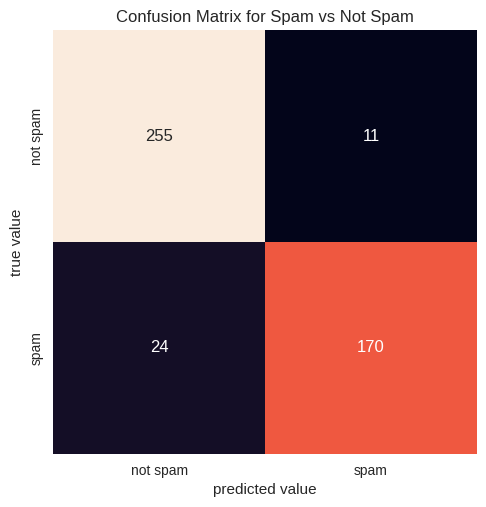

TN 255 FP 11 FN 24 TP 170


In [16]:
# TO DO: Print confusion matrix using a heatmap (1 mark)
mat = confusion_matrix(y_test, y_pred)
sns.heatmap(mat, xticklabels=['not spam', 'spam'], yticklabels=['not spam', 'spam'],
            square=True, annot=True, fmt='d', cbar=False)
plt.xlabel('predicted value')
plt.ylabel('true value')
plt.title("Confusion Matrix for Spam vs Not Spam")
plt.show()
tn, fp, fn, tp = mat.ravel()
print('TN', tn, 'FP', fp, 'FN', fn, 'TP', tp)

### Questions (6 marks)
1. Which model did you select for part 5.2? How did it compare to the other models?
1. Looking at the feature ranges, would a tree-based model or SVM make more sense for this dataset? Did using scaling for SVM improve the results? How did it perform compared to the random forest model?
1. In your opinion, is it better to focus on changing the decision threshold or change the model to improve precision/recall results? Why?

Answer:-
1. We selected RandomForest model for part 5.2. It did better than other models. It had a better training (0.969203) and validation (0.942512) score compared to SVC (Training : 0.719082, Validation : 0.717874) and LogisticRegression (Training : 0.933635, Validation : 0.928019).
1. Tree-based models work best for features with differing scale ranges, therefore, tree-based models makes more sense than SVM. Features need to be scaled before being processed for SVM model whereas tree-based models are scale invariant because each feature is processed seperately. Yes, scaling improved SVM training and validation scores; improving from training score of 0.719082 and validation score of 0.717874 to scores of 0.947826 and 0.931884 respectively using Standard scalar. SVM with scaled features performed comparatively with random forest model. SVM training and validation scores (0.947826 , 0.931884) were near the scores of random forest model (0.969203, 0.942512).          
1. It is better to focus on changing the model than decision threshold to improve precision/recall results because changing the decision threshold trades off precision against recall (improving one degrades other) wherease changing to better model improves both precision and recall. Additionally, sometimes a model performance doesnt improve even after changing decision threshold as its not compatible with the data.

### Process Description (4 marks)
Please describe the process you used to create your code for parts A and B. Cite any websites or generative AI tools used. You can use the following questions as guidance:
1. Where did you source your code?
1. In what order did you complete the steps?
1. If you used generative AI, what prompts did you use? Did you need to modify the code at all? Why or why not?
1. Did you have any challenges? If yes, what were they? If not, what helped you to be successful?

*DESCRIBE YOUR PROCESS HERE - BE SPECIFIC*
1. Code was sourced from class slides and lecture notebooks shared by the professor containing code examples for each case.
2. Same order was followed as the assignment.
3. Generative AI was used to understand some concepts related to questions asked in the previous section. No code was modified using Gen AI.
4. Yes, there were many challenges to understand what should we code. To be successful, we read the code in lecture notebook github repo and class slides to understand the context.

## Part 2: Regression (18 marks)

For this section, we will be using the auto-mpg dataset from assignment 2. You will need to repeat the steps from Part 1 for this analysis.

### Step 1: Data Input

The data used for this task can be downloaded from UCI website: https://archive.ics.uci.edu/ml/datasets/Auto%2BMPG

Load the auto-mpg dataset using the method from assignment 2.

In [17]:
# TO DO: Import auto-mpg data
import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

columns = [
    "mpg", "cylinders", "displacement", "horsepower", "weight",
    "acceleration", "model_year", "origin", "car_name"
]

df = pd.read_csv(
    url,
    sep=r"\s+",
    header=None,
    names=columns,
    na_values="?"
)

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


### Step 2: Data Processing (1 mark)

Follow the same processing steps as the previous assignment.

In [18]:
# TO DO: Process the data - fill-in any missing values and remove any non-numeric columns
# Fill missing horsepower values with the median
df["horsepower"] = df["horsepower"].fillna(df["horsepower"].median())

# Remove the non-numeric car_name column
df = df.drop(columns=["car_name"])

# Check for missing values
print(df.isnull().sum())

mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64


Split the auto-mpg data into the feature matrix and target vector. Inspect the first few columns of the feature matrix to make sure it split properly.

In [19]:
# TO DO: Create feature matrix and target vector
# Feature matrix
X = df.drop(columns=["mpg"])

# Target vector
y = df["mpg"]

# Inspect the features
print(X.head())
print("X shape:", X.shape)
print("y shape:", y.shape)

   cylinders  displacement  horsepower  weight  acceleration  model_year  \
0          8         307.0       130.0  3504.0          12.0          70   
1          8         350.0       165.0  3693.0          11.5          70   
2          8         318.0       150.0  3436.0          11.0          70   
3          8         304.0       150.0  3433.0          12.0          70   
4          8         302.0       140.0  3449.0          10.5          70   

   origin  
0       1  
1       1  
2       1  
3       1  
4       1  
X shape: (398, 7)
y shape: (398,)


### Step 3: Implement and Validate Machine Learning Model (6 marks)

1. Import any required libraries
1. Split the data into training and testing sets (testing data should be 10% of the dataset)
1. Train and validate the Decision Tree model with the training set (use `cross_validate()` with `cv=5` and `scoring='r2'`)
1. Test five different max_depth values: 3, 5, 7, 9 and 11
1. Print the training and validation accuracy for the best max_depth results

**Note**: for any random state parameters, you can use random_state = 0

In [20]:
# Split training and testing sets (1 mark)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.1,
    random_state=0
)

In [21]:
# Test max_depths of 3, 5, 7, 9 and 11 for a decision tree model to find the best results (3 marks)
# Hint: It is easier if you use a loop to evaluate each max_depth
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_validate

depths = [3, 5, 7, 9, 11]

tree_results = []

for depth in depths:
    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=0
    )

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="r2",
        return_train_score=True
    )

    tree_results.append({
        "max_depth": depth,
        "Training R2": scores["train_score"].mean(),
        "Validation R2": scores["test_score"].mean()
    })

tree_results = pd.DataFrame(tree_results)
print(tree_results)

   max_depth  Training R2  Validation R2
0          3     0.827713       0.763391
1          5     0.925157       0.751803
2          7     0.967623       0.782584
3          9     0.989054       0.796413
4         11     0.997188       0.765863


Now that we have found the best results for a decision tree model with this dataset, let's compare this result to using `Random_Forest` or `GradientBoosting`.

In [22]:
# TO DO: Calculate and display training and validation accuracies for both models using default hyperparameters (2 marks)
best_depth = tree_results.loc[
    tree_results["Validation R2"].idxmax(),
    "max_depth"
]

best_tree = DecisionTreeRegressor(
    max_depth=best_depth,
    random_state=0
)

best_tree_scores = cross_validate(
    best_tree,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    return_train_score=True
)

print("Best max_depth:", best_depth)
print("Training R2:", best_tree_scores["train_score"].mean())
print("Validation R2:", best_tree_scores["test_score"].mean())

Best max_depth: 9
Training R2: 0.9890536192362939
Validation R2: 0.7964129492988695


In [23]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_validate

models = {
    "Best Decision Tree": best_tree,
    "Random Forest": RandomForestRegressor(random_state=0),
    "Gradient Boosting": GradientBoostingRegressor(random_state=0)
}

comparison = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="r2",
        return_train_score=True
    )

    comparison.append({
        "Model": name,
        "Training R2": scores["train_score"].mean(),
        "Validation R2": scores["test_score"].mean()
    })

comparison = pd.DataFrame(comparison).set_index("Model")
print(comparison)

                    Training R2  Validation R2
Model                                         
Best Decision Tree     0.989054       0.796413
Random Forest          0.980265       0.866149
Gradient Boosting      0.970852       0.861747


Which model gave us the best results? Use that model for the next step.

### Step 4: Test Model (1 mark)

Select the best model and calculate the testing accuracy using the R^2 score

In [24]:
# TO DO: Find test score using best model (1 mark)
# Choose the model with the highest validation R2
best_model_name = comparison["Validation R2"].idxmax()
best_model = models[best_model_name]

# Fit using the full training set
best_model.fit(X_train, y_train)

# Predict the test set
y_test_pred = best_model.predict(X_test)

# Calculate test R2
from sklearn.metrics import r2_score

test_r2 = r2_score(y_test, y_test_pred)

print("Best model:", best_model_name)
print("Test R2:", test_r2)

Best model: Random Forest
Test R2: 0.930150386559485


### Questions (6 marks)
1. Which model gave us the best results? Did you compare training accuracy or validation accuracy to determine this?
1. How did the models perform compared to each other and the linear model from the previous assignment? Use numbers.
1. List two ways we could further improve the results.

*ANSWER HERE*

1. The Random Forest gave the best results. We compared validation R², not training R², because validation R² shows how well the model generalizes. For example, the decision tree had a training R² of 0.989 but a validation R² of only 0.796, which is overfitting.

2. The Random Forest performed best with a mean validation R² of 0.866. Gradient Boosting was close behind at 0.862, and the best decision tree (max_depth=9) had 0.796. The linear regression from Assignment 2 had a validation R² of 0.808 (test 0.845). So Random Forest and Gradient Boosting performed better than linear regression, while the single decision tree was slightly worse. On the test set, the Random Forest reached an R² of 0.930 compared with 0.845 for linear regression. This makes sense because the pairplot showed curved (non-linear) relationships that a straight line can’t capture. The test set is only 40 cars, so its score is less stable than the cross-validation score.

3. Ways to could further improve the results:
*   Tune the hyperparameters: Use grid search or randomized search to find better settings for parameters such as max_depth, n_estimators, min_samples_split, and min_samples_leaf.
*   Improve the features: Explore feature engineering, such as creating useful combinations of existing features, and evaluate whether removing irrelevant features improves validation performance.

### Process Description (4 marks)
Please describe the process you used to create your code. Cite any websites or generative AI tools used. You can use the following questions as guidance:
1. Where did you source your code?
1. In what order did you complete the steps?
1. If you used generative AI, what prompts did you use? Did you need to modify the code at all? Why or why not?
1. Did you have any challenges? If yes, what were they? If not, what helped you to be successful?

1. Code came from the class slides and lecture notebooks, plus our own Assignment 2 code. We used scikit-learn documentation for SVC, RandomForestClassifier and the scalers. We also used Claude (Anthropic) to review our work.
2. We followed the order of the assignment: 1A first, then 1B.
3. Generative AI was used to understand some concepts related to questions asked in the previous section. No code was modified using Gen AI.
4. Yes, there were many challenges to understand what should we code. To be successful, we read the code in lecture notebook github repo and class slides to understand the context.

*DESCRIBE YOUR PROCESS HERE - BE SPECIFIC*

## Part 3: Reflection (2 marks)
Include a sentence or two about:
- what you liked or disliked,
- found interesting, confusing, challenging, motivating
while working on this assignment.


*ADD YOUR THOUGHTS HERE*